In [1]:
import pandas as pd
import matplotlib.pyplot as plt 

Na linha abaixo, foi feita a limpeza do dataframe. Foi retirado colunas que apresentavam algum valor ausente e nesse notebook em especifico foi deixado a coluna point e os lugares vazios foram preenchidos com 0.

In [2]:
df = pd.read_csv("f1_dnf.csv")
df['points'].fillna(0, inplace=True)
df.dropna(axis=1,how='any')
df.replace('\\N', pd.NA, inplace=True)


df.dropna(axis=1, inplace=True)



df.head()

C:\Users\Irisd\AppData\Local\Temp\ipykernel_27704\1462876967.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['points'].fillna(0, inplace=True)


,resultId,raceId,year,round,grid,positionOrder,points,driverRef,surname,forename,...,circuitRef,circuitId,name_y,location,country,lat,lng,alt,date,target_finish
0,2460,136,2002,13,11,4,3.0,raikkonen,Räikkönen,Kimi,...,hungaroring,11,McLaren,Budapest,Hungary,47.5789,19.24860,264,2002-08-18,1
1,11565,483,1981,1,23,21,0.0,watson,Watson,John,...,long_beach,43,McLaren,California,USA,33.7651,-118.18900,12,1981-03-15,0
2,18661,772,1958,8,0,26,0.0,ruttman,Ruttman,Troy,...,nurburgring,20,Maserati,Nürburg,Germany,50.3356,6.94750,578,1958-08-03,0
3,25121,1058,2021,8,19,16,0.0,mick_schumacher,Schumacher,Mick,...,red_bull_ring,70,Haas F1 Team,Spielberg,Austria,47.2197,14.76470,678,2021-06-27,0
4,8863,383,1988,12,0,30,0.0,modena,Modena,Stefano,...,monza,14,Euro Brun,Monza,Italy,45.6156,9.28111,162,1988-09-11,0


O gráfico exibe a quantidade total de corridas concluídas por temporada, mostrando como esse número variou ao longo dos anos.
Os dados são agrupados por ano e representados em uma linha azul, destacando períodos de aumento ou queda no total de corridas finalizadas.
Essa visualização permite identificar tendências na regularidade das provas e possíveis mudanças no calendário ou na confiabilidade dos carros.

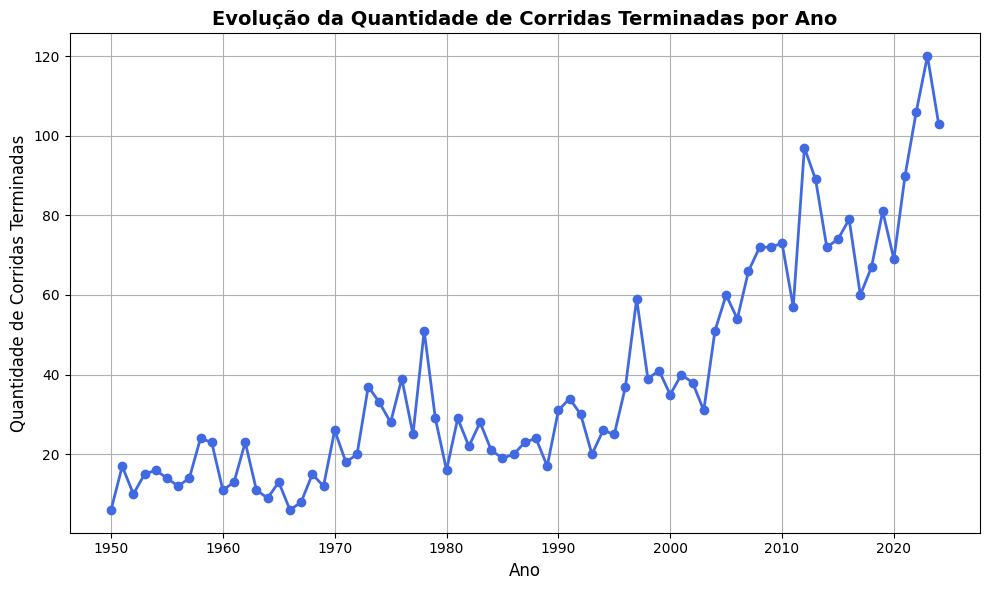

In [ ]:



df_terminadas = df[df['target_finish'] == 1]


corridas_por_ano = df_terminadas.groupby('year').size()


plt.figure(figsize=(10,6))
plt.plot(corridas_por_ano.index, corridas_por_ano.values, marker='o', color='royalblue', linewidth=2)


plt.title("Evolução da Quantidade de Corridas Terminadas por Ano", fontsize=14, fontweight='bold')
plt.xlabel("Ano", fontsize=12)
plt.ylabel("Quantidade de Corridas Terminadas", fontsize=12)


plt.grid(True)

plt.tight_layout()
plt.show()


O gráfico mostra como evoluíram, ao longo dos anos, a pontuação média e a posição média de chegada dos pilotos.
A linha azul representa a média de pontos marcados por temporada, enquanto a vermelha indica a posição média obtida ( quanto mais baixa, melhor).
Essa comparação permite observar se o aumento de pontos ao longo do tempo acompanha uma melhora no desempenho médio dos pilotos.

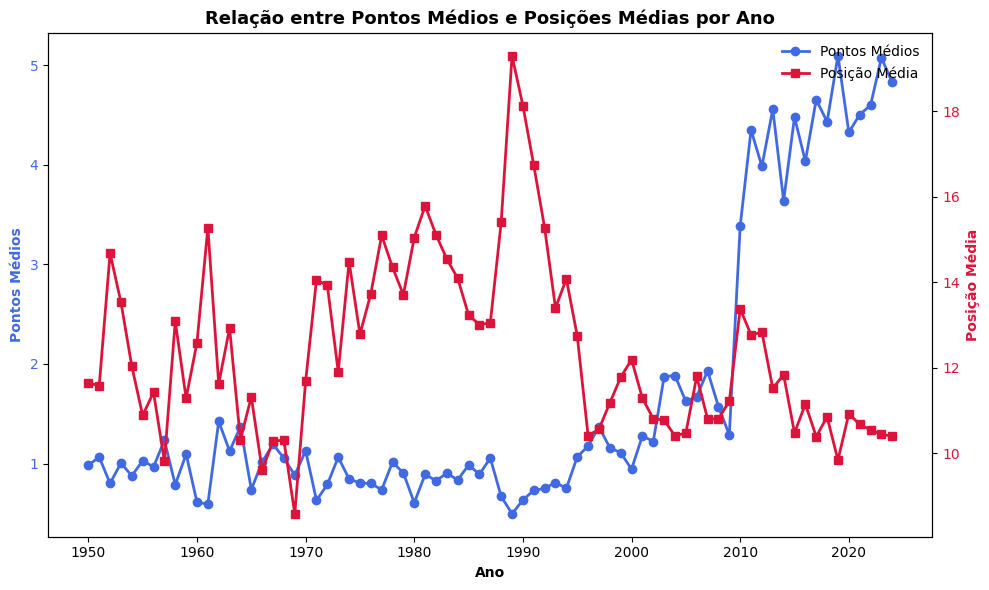

In [ ]:



df['points'] = pd.to_numeric(df['points'], errors='coerce').fillna(0)
df['positionOrder'] = pd.to_numeric(df['positionOrder'], errors='coerce').fillna(0)


df_group = df.groupby('year').agg({
    'points': 'mean',
    'positionOrder': 'mean'
}).reset_index()

fig, ax1 = plt.subplots(figsize=(10,6))

# Serie 1
ax1.plot(df_group['year'], df_group['points'], color='royalblue', marker='o', linewidth=2, label='Pontos Médios')
ax1.set_xlabel("Ano", fontweight='bold')
ax1.set_ylabel("Pontos Médios", color='royalblue', fontweight='bold')
ax1.tick_params(axis='y', labelcolor='royalblue')

# Serie 2
ax2 = ax1.twinx() #isso faz o gemeo do eixo
ax2.plot(df_group['year'], df_group['positionOrder'], color='crimson', marker='s', linewidth=2, label='Posição Média')
ax2.set_ylabel("Posição Média", color='crimson', fontweight='bold')
ax2.tick_params(axis='y', labelcolor='crimson')





plt.title("Relação entre Pontos Médios e Posições Médias por Ano", fontweight='bold', fontsize=13)
fig.tight_layout()


lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines1 + lines2, labels1 + labels2, loc='upper right', frameon=False)

plt.show()
